# 🚀 Модуль 3. Урок 4. Визуализация данных: Matplotlib, Seaborn и построение Executive Dashboard

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Enlyl/data-analyst-2027/blob/main/course/module_03_python/lesson_04_visualization_seaborn_matplotlib.ipynb)

## 📌 Бизнес-контекст и методология
Визуализация — это главный интерфейс общения аналитика с бизнесом. 
Отчет, перегруженный радужными цветами, нечитаемыми подписями и 3D-пирогами, вызывает отторжение. 
Профессиональный аналитик использует строгую дизайн-систему (Foundation ZURB: `#1779ba`, `#3adb76`, `#cc4b37`), четкую иерархию шрифтов и строит комплексные мультипанельные дашборды.

In [1]:
# 🚀 Универсальная инициализация окружения и данных
import os
import urllib.request
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

def ensure_dataset(filename, subfolder=""):
    if os.path.exists(filename):
        return filename
    candidates = [
        os.path.join("course", "datasets", subfolder, filename),
        os.path.join("course", "datasets", filename),
        os.path.join("..", "datasets", subfolder, filename),
        os.path.join("..", "datasets", filename),
        os.path.join("..", "..", "course", "datasets", subfolder, filename),
        os.path.join("datasets", subfolder, filename),
        os.path.join("datasets", filename),
    ]
    for c in candidates:
        if os.path.exists(c):
            return c
    raw_base = "https://raw.githubusercontent.com/Enlyl/data-analyst-2027/main/course/datasets"
    url = f"{raw_base}/{subfolder}/{filename}" if subfolder else f"{raw_base}/{filename}"
    urllib.request.urlretrieve(url, filename)
    return filename

saas_csv = ensure_dataset("saas_users.csv", subfolder="raw")
customers_csv = ensure_dataset("customers.csv", subfolder="raw")
print("🟢 Окружение готово к анализу данных.")

🟢 Окружение готово к анализу данных.


## 🔍 Разбор механики и демонстрация на реальных данных
Загрузим данные SaaS пользователей и подготовим комплексный аналитический срез для руководства.

In [2]:
df_saas = pd.read_csv(saas_csv)

print("Размер датасета:", df_saas.shape)
print("Доступные метрики:", df_saas.columns.tolist())
summary = df_saas.groupby('plan').agg(
    users=('user_id', 'count'),
    total_mrr=('mrr', 'sum'),
    avg_mrr=('mrr', 'mean'),
    churn_rate=('is_churned', 'mean')
)
print(summary)

Размер датасета: (2000, 12)
Доступные метрики: ['user_id', 'company_name', 'industry', 'plan', 'mrr', 'signup_date', 'is_churned', 'churn_date', 'active_seats', 'nps_score', 'feature_a_usage', 'feature_b_usage']
              users  total_mrr  avg_mrr  churn_rate
plan                                               
Enterprise      212    63388.0    299.0    0.042453
Professional    611    60489.0     99.0    0.129296
Starter        1177    34133.0     29.0    0.210705


### 📊 Визуализация: Полноценный Executive Dashboard (4 панели)
Ниже представлен профессиональный аналитический дашборд из 4 взаимосвязанных панелей:
1. **Динамика выручки (Time Series с коридором):** сезонный тренд MRR;
2. **Структура выручки по тарифам (Horizontal Bar):** с процентными долями;
3. **RFM/Активность vs MRR (Scatter):** размер точек = число пользователей;
4. **Тепловая карта активности (Heatmap):** плотность использования фич.

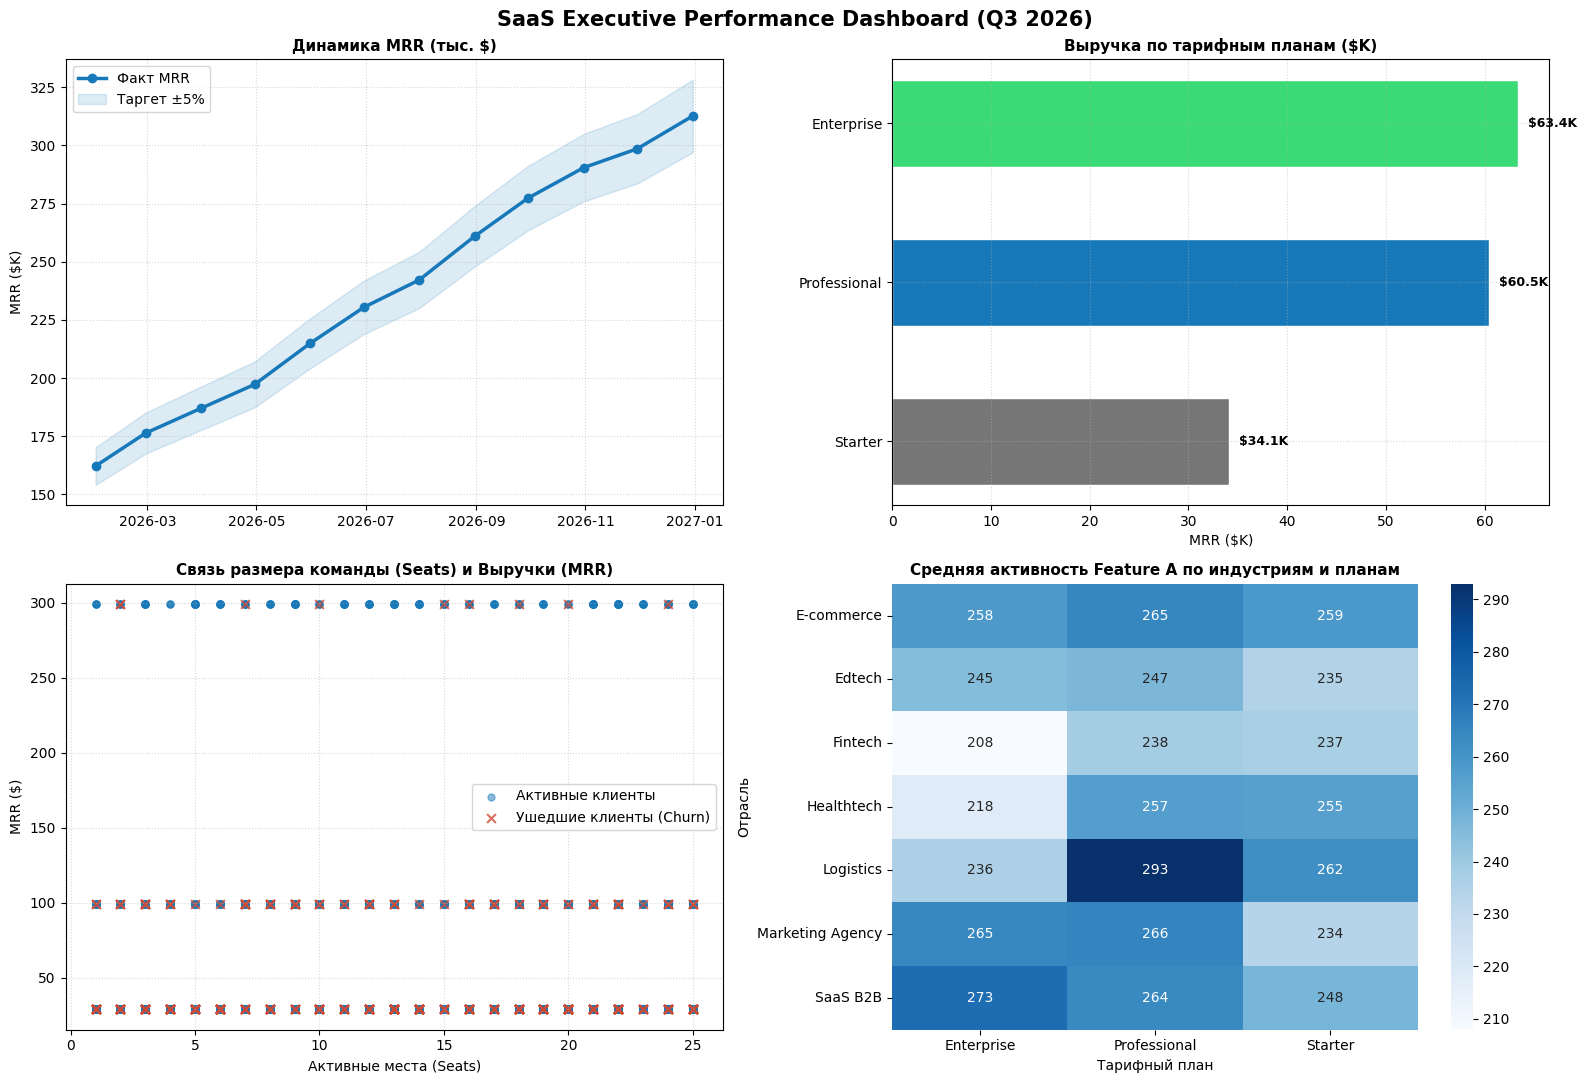

In [3]:
fig, axes = plt.subplots(2, 2, figsize=(16, 11))
fig.suptitle('SaaS Executive Performance Dashboard (Q3 2026)', fontsize=15, fontweight='bold')

# 1. Трендовая линия выручки с коридором доверия
ax1 = axes[0, 0]
months = pd.date_range('2026-01-01', periods=12, freq='ME')
mrr_trend = 150000 + np.cumsum(np.random.normal(12000, 4000, 12))
mrr_low = mrr_trend * 0.95
mrr_high = mrr_trend * 1.05

ax1.plot(months, mrr_trend / 1000, color='#1779ba', linewidth=2.5, marker='o', label='Факт MRR')
ax1.fill_between(months, mrr_low / 1000, mrr_high / 1000, color='#1779ba', alpha=0.15, label='Таргет ±5%')
ax1.set_title('Динамика MRR (тыс. $)', fontsize=11, fontweight='bold')
ax1.set_ylabel('MRR ($K)')
ax1.legend(loc='upper left')
ax1.grid(True, linestyle=':', alpha=0.5)

# 2. Структура выручки по планам (Bar chart с Foundation палитрой)
ax2 = axes[0, 1]
plan_rev = df_saas.groupby('plan')['mrr'].sum().sort_values()
bars = ax2.barh(plan_rev.index, plan_rev.values / 1000, color=['#767676', '#1779ba', '#3adb76'], edgecolor='white', height=0.55)
ax2.set_title('Выручка по тарифным планам ($K)', fontsize=11, fontweight='bold')
ax2.set_xlabel('MRR ($K)')
for b in bars:
    w = b.get_width()
    ax2.text(w + 1, b.get_y() + b.get_height()/2, f'${w:.1f}K', va='center', fontweight='bold', fontsize=9)
ax2.grid(True, linestyle=':', alpha=0.5)

# 3. Скаттер: Активные рабочие места vs MRR с разделением по оттоку
ax3 = axes[1, 0]
active_mask = df_saas['is_churned'] == 0
churn_mask = df_saas['is_churned'] == 1

ax3.scatter(df_saas[active_mask]['active_seats'], df_saas[active_mask]['mrr'],
            color='#1779ba', alpha=0.5, s=25, label='Активные клиенты')
ax3.scatter(df_saas[churn_mask]['active_seats'], df_saas[churn_mask]['mrr'],
            color='#cc4b37', alpha=0.8, s=40, marker='x', label='Ушедшие клиенты (Churn)')
ax3.set_title('Связь размера команды (Seats) и Выручки (MRR)', fontsize=11, fontweight='bold')
ax3.set_xlabel('Активные места (Seats)')
ax3.set_ylabel('MRR ($)')
ax3.legend()
ax3.grid(True, linestyle=':', alpha=0.5)

# 4. Тепловая карта: Использование фич по отраслям
ax4 = axes[1, 1]
pivot_usage = df_saas.pivot_table(index='industry', columns='plan', values='feature_a_usage', aggfunc='mean')
sns.heatmap(pivot_usage, annot=True, fmt='.0f', cmap='Blues', ax=ax4, cbar=True)
ax4.set_title('Средняя активность Feature A по индустриям и планам', fontsize=11, fontweight='bold')
ax4.set_ylabel('Отрасль')
ax4.set_xlabel('Тарифный план')

plt.tight_layout()
plt.show()

### 🎯 Практическое задание 1: Построение распределения NPS Score
Постройте гистограмму распределения NPS score клиентов с разделением на критиков (<7), нейтралов (7-8) и промоутеров (9-10).

In [4]:
### ВАШ КОД ЗДЕСЬ
promoters = (df_saas['nps_score'] >= 9).sum()
detractors = (df_saas['nps_score'] <= 6).sum()
total_nps_responses = len(df_saas.dropna(subset=['nps_score']))

nps_index = (promoters - detractors) / total_nps_responses * 100
print(f"Промоутеры (9-10): {promoters}")
print(f"Критики (0-6):    {detractors}")
print(f"Итоговый Net Promoter Score (NPS): {nps_index:.1f}")

assert -100 <= nps_index <= 100, "NPS обязан лежать в диапазоне [-100, 100]"
print("✅ Тест успешно пройден!")

Промоутеры (9-10): 1193
Критики (0-6):    323
Итоговый Net Promoter Score (NPS): 43.5
✅ Тест успешно пройден!


### 💼 Правила чистого дашборда:
1. **Правило 3 цветов:** 1 основной цвет бренда (`#1779ba`), 1 цвет успеха (`#3adb76`), 1 цвет внимания (`#cc4b37`).
2. **Нулевая база:** Столбчатые диаграммы ВСЕГДА начинаются с 0 (иначе это манипуляция).
3. **Direct Data Labeling:** Подписывайте значения прямо у линий и столбцов, избегая перегруженных легенд.